# **Breast Cancer Prediction with TensorFlow / Keras (Binary Classification)**

**Dataset:** Breast Cancer Wisconsin — 30 numeric features,
predict whether a tumor is *malignant* or *benign*.

**The pipeline we'll establish here is the template for every project in this section:**
load → explore → split → scale → build → train → evaluate.

## **1. Imports & Setup**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (confusion_matrix, classification_report, roc_auc_score, roc_curve)

In [2]:
# set seeds for reproducible results
np.random.seed(42)
tf.random.set_seed(42)

# configurations
pd.set_option('display.max_columns', None)                          # show all columns, don't truncate
pd.set_option('display.float_format', lambda x: f'{x:.4f}')         # no scientific notation, 4 decimals
np.set_printoptions(suppress=True)                                  # no scientific notation for numpy arrays

## **2. Load the data**

In [3]:
df = pd.read_csv('breast_cancer_data.csv')
df.head(10)

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.9900,10.3800,122.8000,1001.0000,0.1184,0.2776,0.3001,0.1471,0.2419,0.0787,1.0950,0.9053,8.5890,153.4000,0.0064,0.0490,0.0537,0.0159,0.0300,0.0062,25.3800,17.3300,184.6000,2019.0000,0.1622,0.6656,0.7119,0.2654,0.4601,0.1189,NaN
1,842517,M,20.5700,17.7700,132.9000,1326.0000,0.0847,0.0786,0.0869,0.0702,0.1812,0.0567,0.5435,0.7339,3.3980,74.0800,0.0052,0.0131,0.0186,0.0134,0.0139,0.0035,24.9900,23.4100,158.8000,1956.0000,0.1238,0.1866,0.2416,0.1860,0.2750,0.0890,NaN
2,84300903,M,19.6900,21.2500,130.0000,1203.0000,0.1096,0.1599,0.1974,0.1279,0.2069,0.0600,0.7456,0.7869,4.5850,94.0300,0.0062,0.0401,0.0383,0.0206,0.0225,0.0046,23.5700,25.5300,152.5000,1709.0000,0.1444,0.4245,0.4504,0.2430,0.3613,0.0876,NaN
3,84348301,M,11.4200,20.3800,77.5800,386.1000,0.1425,0.2839,0.2414,0.1052,0.2597,0.0974,0.4956,1.1560,3.4450,27.2300,0.0091,0.0746,0.0566,0.0187,0.0596,0.0092,14.9100,26.5000,98.8700,567.7000,0.2098,0.8663,0.6869,0.2575,0.6638,0.1730,NaN
4,84358402,M,20.2900,14.3400,135.1000,1297.0000,0.1003,0.1328,0.1980,0.1043,0.1809,0.0588,0.7572,0.7813,5.4380,94.4400,0.0115,0.0246,0.0569,0.0188,0.0176,0.0051,22.5400,16.6700,152.2000,1575.0000,0.1374,0.2050,0.4000,0.1625,0.2364,0.0768,NaN
5,843786,M,12.4500,15.7000,82.5700,477.1000,0.1278,0.1700,0.1578,0.0809,0.2087,0.0761,0.3345,0.8902,2.2170,27.1900,0.0075,0.0335,0.0367,0.0114,0.0216,0.0051,15.4700,23.7500,103.4000,741.6000,0.1791,0.5249,0.5355,0.1741,0.3985,0.1244,NaN
6,844359,M,18.2500,19.9800,119.6000,1040.0000,0.0946,0.1090,0.1127,0.0740,0.1794,0.0574,0.4467,0.7732,3.1800,53.9100,0.0043,0.0138,0.0225,0.0104,0.0137,0.0022,22.8800,27.6600,153.2000,1606.0000,0.1442,0.2576,0.3784,0.1932,0.3063,0.0837,NaN
7,84458202,M,13.7100,20.8300,90.2000,577.9000,0.1189,0.1645,0.0937,0.0599,0.2196,0.0745,0.5835,1.3770,3.8560,50.9600,0.0088,0.0303,0.0249,0.0145,0.0149,0.0054,17.0600,28.1400,110.6000,897.0000,0.1654,0.3682,0.2678,0.1556,0.3196,0.1151,NaN
8,844981,M,13.0000,21.8200,87.5000,519.8000,0.1273,0.1932,0.1859,0.0935,0.2350,0.0739,0.3063,1.0020,2.4060,24.3200,0.0057,0.0350,0.0355,0.0123,0.0214,0.0037,15.4900,30.7300,106.2000,739.3000,0.1703,0.5401,0.5390,0.2060,0.4378,0.1072,NaN
9,84501001,M,12.4600,24.0400,83.9700,475.9000,0.1186,0.2396,0.2273,0.0854,0.2030,0.0824,0.2976,1.5990,2.0390,23.9400,0.0071,0.0722,0.0774,0.0143,0.0179,0.0101,15.0900,40.6800,97.6500,711.4000,0.1853,1.0580,1.1050,0.2210,0.4366,0.2075,NaN


## **3. Quick Exploration**

In [4]:
df.shape

(569, 33)

In [5]:
# drop "id" and "Unnamed: 32" colummns
df = df.drop(columns=['id', 'Unnamed: 32'])

In [6]:
# convert labels to 1 and 0
df['diagnosis'] = df['diagnosis'].map({'B': 0, 'M': 1}).astype(int)

In [7]:
df.head()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,1,17.9900,10.3800,122.8000,1001.0000,0.1184,0.2776,0.3001,0.1471,0.2419,0.0787,1.0950,0.9053,8.5890,153.4000,0.0064,0.0490,0.0537,0.0159,0.0300,0.0062,25.3800,17.3300,184.6000,2019.0000,0.1622,0.6656,0.7119,0.2654,0.4601,0.1189
1,1,20.5700,17.7700,132.9000,1326.0000,0.0847,0.0786,0.0869,0.0702,0.1812,0.0567,0.5435,0.7339,3.3980,74.0800,0.0052,0.0131,0.0186,0.0134,0.0139,0.0035,24.9900,23.4100,158.8000,1956.0000,0.1238,0.1866,0.2416,0.1860,0.2750,0.0890
2,1,19.6900,21.2500,130.0000,1203.0000,0.1096,0.1599,0.1974,0.1279,0.2069,0.0600,0.7456,0.7869,4.5850,94.0300,0.0062,0.0401,0.0383,0.0206,0.0225,0.0046,23.5700,25.5300,152.5000,1709.0000,0.1444,0.4245,0.4504,0.2430,0.3613,0.0876
3,1,11.4200,20.3800,77.5800,386.1000,0.1425,0.2839,0.2414,0.1052,0.2597,0.0974,0.4956,1.1560,3.4450,27.2300,0.0091,0.0746,0.0566,0.0187,0.0596,0.0092,14.9100,26.5000,98.8700,567.7000,0.2098,0.8663,0.6869,0.2575,0.6638,0.1730
4,1,20.2900,14.3400,135.1000,1297.0000,0.1003,0.1328,0.1980,0.1043,0.1809,0.0588,0.7572,0.7813,5.4380,94.4400,0.0115,0.0246,0.0569,0.0188,0.0176,0.0051,22.5400,16.6700,152.2000,1575.0000,0.1374,0.2050,0.4000,0.1625,0.2364,0.0768


In [8]:
df['diagnosis'].value_counts()

diagnosis
0    357
1    212
Name: count, dtype: int64

In [9]:
df['diagnosis'].value_counts(normalize=True) * 100

diagnosis
0   62.7417
1   37.2583
Name: proportion, dtype: float64

## **4. Train/Val/Test Split**

In [10]:
X = df.drop(columns=['diagnosis'])
y = df['diagnosis']

In [11]:
X.head()

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,17.9900,10.3800,122.8000,1001.0000,0.1184,0.2776,0.3001,0.1471,0.2419,0.0787,1.0950,0.9053,8.5890,153.4000,0.0064,0.0490,0.0537,0.0159,0.0300,0.0062,25.3800,17.3300,184.6000,2019.0000,0.1622,0.6656,0.7119,0.2654,0.4601,0.1189
1,20.5700,17.7700,132.9000,1326.0000,0.0847,0.0786,0.0869,0.0702,0.1812,0.0567,0.5435,0.7339,3.3980,74.0800,0.0052,0.0131,0.0186,0.0134,0.0139,0.0035,24.9900,23.4100,158.8000,1956.0000,0.1238,0.1866,0.2416,0.1860,0.2750,0.0890
2,19.6900,21.2500,130.0000,1203.0000,0.1096,0.1599,0.1974,0.1279,0.2069,0.0600,0.7456,0.7869,4.5850,94.0300,0.0062,0.0401,0.0383,0.0206,0.0225,0.0046,23.5700,25.5300,152.5000,1709.0000,0.1444,0.4245,0.4504,0.2430,0.3613,0.0876
3,11.4200,20.3800,77.5800,386.1000,0.1425,0.2839,0.2414,0.1052,0.2597,0.0974,0.4956,1.1560,3.4450,27.2300,0.0091,0.0746,0.0566,0.0187,0.0596,0.0092,14.9100,26.5000,98.8700,567.7000,0.2098,0.8663,0.6869,0.2575,0.6638,0.1730
4,20.2900,14.3400,135.1000,1297.0000,0.1003,0.1328,0.1980,0.1043,0.1809,0.0588,0.7572,0.7813,5.4380,94.4400,0.0115,0.0246,0.0569,0.0188,0.0176,0.0051,22.5400,16.6700,152.2000,1575.0000,0.1374,0.2050,0.4000,0.1625,0.2364,0.0768


In [12]:
y.sample(5)

204    0
70     1
131    1
431    0
540    0
Name: diagnosis, dtype: int32

In [13]:
# first peel off the test set (20%)
X_train_full, X_test, y_train_full, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# then split the rest (X_train_full) into train (60%) and validation (20%)
X_train, X_val, y_train, y_val = train_test_split(X_train_full, y_train_full, test_size=0.25, stratify=y_train_full, random_state=42)

print("Train", X_train.shape)
print("Val", X_val.shape)
print("Test", X_test.shape)

Train (341, 30)
Val (114, 30)
Test (114, 30)


## **5. Scale the features**

In [14]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

## **6. Build the model**

In [15]:
model = keras.Sequential([
     keras.Input(shape=(X_train.shape[1],)),
     keras.layers.Dense(16, activation='relu'),
     keras.layers.Dense(8, activation='relu'),
     keras.layers.Dense(1, activation='sigmoid')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 641 (2.50 KB)

 Trainable params: 641 (2.50 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
# compile the model
model.compile(
     optimizer=keras.optimizers.Adam(learning_rate=0.001),
     loss='binary_crossentropy',
     metrics=['accuracy']
)

## **7. Training**

In [17]:
# Early stopping to prevent overfitting and save training time
early_stop = keras.callbacks.EarlyStopping(
     monitor='val_loss', patience=10, restore_best_weights=True
)

In [18]:
class printevery10(keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs):
        if (epoch + 1) % 10 == 0:
            print(f"epoch {epoch + 1:3d}  "
                  f"loss {logs['loss']:.4f}  acc {logs['accuracy']:.4f}  "
                  f"val_loss {logs['val_loss']:.4f}  val_acc {logs['val_accuracy']:.4f}")

In [19]:
history = model.fit(
     X_train, y_train,
     validation_data=(X_val, y_val),
     epochs=100,
     batch_size=32,
     callbacks=[early_stop, printevery10()],
     verbose=0
)

epoch  10  loss 0.2243  acc 0.9413  val_loss 0.2184  val_acc 0.9474
epoch  20  loss 0.0967  acc 0.9795  val_loss 0.1079  val_acc 0.9737
epoch  30  loss 0.0670  acc 0.9853  val_loss 0.0850  val_acc 0.9649
epoch  40  loss 0.0501  acc 0.9912  val_loss 0.0764  val_acc 0.9649
epoch  50  loss 0.0385  acc 0.9912  val_loss 0.0721  val_acc 0.9649
epoch  60  loss 0.0301  acc 0.9912  val_loss 0.0701  val_acc 0.9649
epoch  70  loss 0.0232  acc 0.9941  val_loss 0.0673  val_acc 0.9649
epoch  80  loss 0.0179  acc 0.9971  val_loss 0.0654  val_acc 0.9737
epoch  90  loss 0.0137  acc 0.9971  val_loss 0.0641  val_acc 0.9737
epoch 100  loss 0.0106  acc 1.0000  val_loss 0.0634  val_acc 0.9737


In [20]:
print("Trained for", len(history.history["loss"]))

Trained for 100


## **8. Learning Curves**

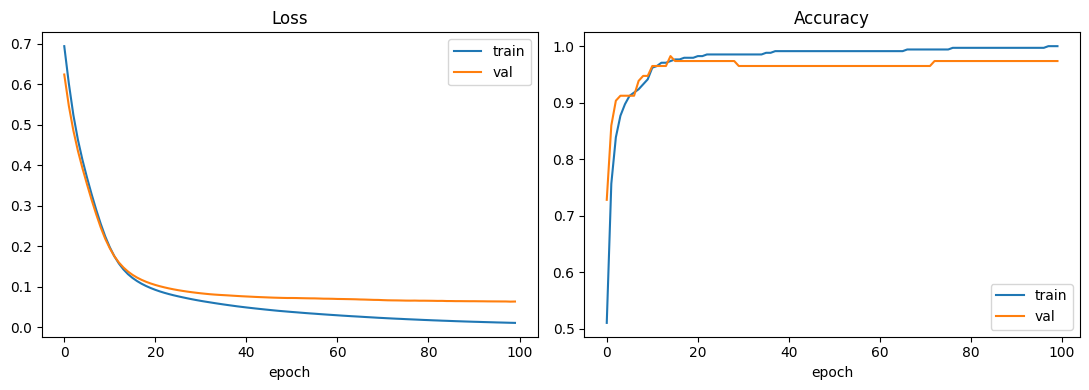

In [21]:
hist = history.history

plt.figure(figsize=(11, 4))
plt.subplot(1 ,2 ,1)
plt.plot(hist['loss'], label='train')
plt.plot(hist['val_loss'], label='val')
plt.title('Loss'); plt.xlabel('epoch'); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(hist['accuracy'], label='train')
plt.plot(hist['val_accuracy'], label='val')
plt.title("Accuracy"); plt.xlabel("epoch"); plt.legend()

plt.tight_layout()
plt.show()

## **9. Evaluate on the test set**

In [22]:
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print("Test loss:", round(test_loss, 3))
print("Test accuracy:", round(test_acc, 3))

Test loss: 0.094
Test accuracy: 0.965


In [23]:
y_prob = model.predict(X_test, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print("First 5 probabilities:", y_prob[:5].round(3))
print("First 5 predictions:  ", y_pred[:5])

First 5 probabilities: [0.    1.    0.011 0.925 0.894]
First 5 predictions:   [0 1 0 1 1]


## **10. Confusion Matrix**

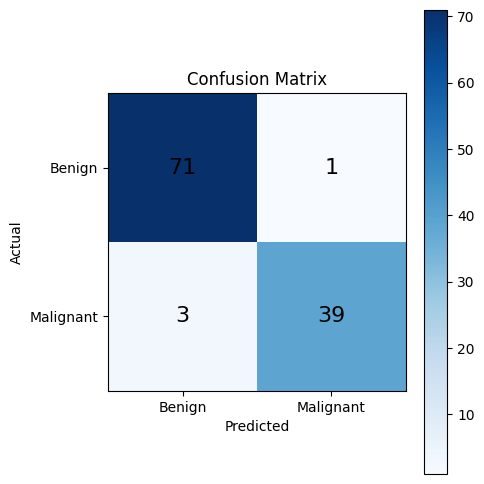

In [24]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5, 5))
plt.imshow(cm, interpolation='nearest', cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.xticks(ticks=[0, 1], labels=['Benign', 'Malignant'])
plt.yticks(ticks=[0, 1], labels=['Benign', 'Malignant'])
for i in range(2):
    for j in range(2):
            plt.text(j, i, cm[i, j], ha='center', va='center', fontsize=16)
plt.colorbar()
plt.tight_layout()
plt.show()

## **11. Precision, recall, F1**

In [25]:
print(classification_report(y_test, y_pred, target_names=['Benign', 'Malignant']))

              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        72
   Malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



## **12. ROC curve & AUC**

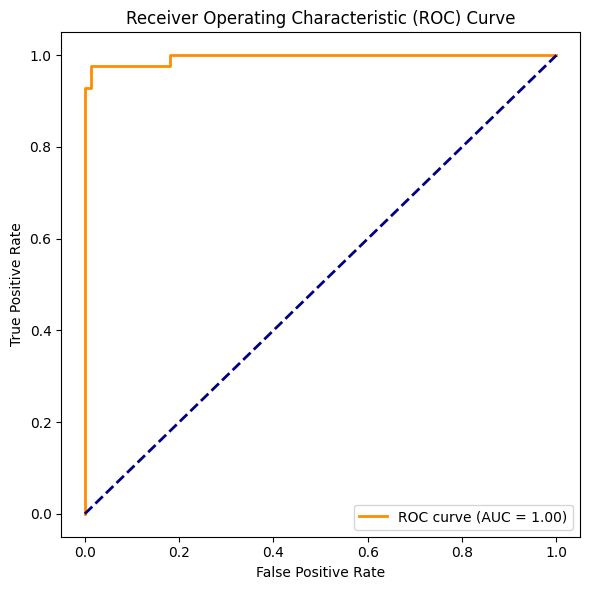

In [26]:
auc = roc_auc_score(y_test, y_prob)
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## **13. Save the model & the scaler**

In [27]:
import joblib

# save the model
model.save("breast_cancer_model.keras")

# saving the scaler
joblib.dump(scaler, "scaler.joblib")

print("Saved: breast_cancer_model.keras, scaler.joblib")

Saved: breast_cancer_model.keras, scaler.joblib
